<a href="https://colab.research.google.com/github/TomoShishido/img2xml/blob/main/img2xml.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# img2Mxml (sheetmusic2musicxml): produce a music xml file from a sheet music image (.jpg or .png)

In [ ]:
!pip uninstall -y torch torchvision
#!pip install torch==1.8.1 
!pip install torchvision==0.9.1

Looking in indexes: https://pypi.org/simple, https://us-python.pkg.dev/colab-wheels/public/simple/
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 17.4/17.4 MB 82.7 MB/s eta 0:00:00
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 804.1/804.1 MB 2.2 MB/s eta 0:00:00
ERROR: pip's dependency resolver does not currently take into account all the packages that are installed. This behaviour is the source of the following dependency conflicts.
fastai 2.7.10 requires pandas, which is not installed.
torchtext 0.14.1 requires torch==1.13.1, but you have torch 1.8.1 which is incompatible.
torchaudio 0.13.1+cu116 requires torch==1.13.1, but you have torch 1.8.1 which is incompatible.


In [ ]:
import torch
torch.__version__

'1.8.1+cu102'

In [ ]:
!git clone https://github.com/TomoShishido/img2xml  # clone repo

Cloning into 'img2xml'...
remote: Enumerating objects: 1127, done.
remote: Counting objects: 100% (1127/1127), done.
remote: Compressing objects: 100% (914/914), done.
remote: Total 1127 (delta 126), reused 1089 (delta 94), pack-reused 0
Receiving objects: 100% (1127/1127), 35.86 MiB | 24.13 MiB/s, done.
Resolving deltas: 100% (126/126), done.


In [ ]:

#!pip install -qr img2xml/bfaaap/requirements.txt  # install dependencies (ignore errors)
%cd /content/img2xml/bfaaap/yolov5

import torch
from IPython.display import Image, clear_output  # to display images
from utils.google_utils import gdrive_download  # to download models/datasets

clear_output()
print('Setup complete. Using torch %s %s' % (torch.__version__, torch.cuda.get_device_properties(0) if torch.cuda.is_available() else 'CPU'))

Setup complete. Using torch 1.8.1+cu102 _CudaDeviceProperties(name='Tesla T4', major=7, minor=5, total_memory=15109MB, multi_processor_count=40)


In [ ]:
#!echo "import torch; print(torch.__version__)" > /tmp/print_torch_version.py
#!python3.9 /tmp/print_torch_version.py

In [ ]:
!ls -l /content/img2xml/bfaaap/

total 64
drwxr-xr-x 2 root root  4096 Feb  4 00:34 adjustalphabeta
drwxr-xr-x 3 root root  4096 Feb  4 00:34 alignmeasures
-rw-r--r-- 1 root root  8735 Feb  4 00:34 detectionintegration.py
drwxr-xr-x 4 root root  4096 Feb  4 00:34 enlargemeasures
drwxr-xr-x 2 root root  4096 Feb  4 00:34 leveloriginalimg
drwxr-xr-x 2 root root  4096 Feb  4 00:34 makeyolomusicdict
drwxr-xr-x 5 root root  4096 Feb  4 00:34 musicdata
-rw-r--r-- 1 root root  1630 Feb  4 00:34 requirements_for_localenv.txt
-rw-r--r-- 1 root root    77 Feb  4 00:34 requirements.txt
-rw-r--r-- 1 root root 10358 Feb  4 00:34 systemintegration.py
drwxr-xr-x 3 root root  4096 Feb  4 00:34 yoloToxml
drwxr-xr-x 6 root root  4096 Feb  4 00:36 yolov5


In [ ]:
from google.colab import drive
drive.mount('/content/g')

Mounted at /content/g


In [ ]:
!ls /content/g/

MyDrive


In [ ]:
# place yolov5 weights in /bfaaap/yolov5/weightsstock/
!mkdir /content/img2xml/bfaaap/yolov5/weightsstock
%cd /content/img2xml/bfaaap/yolov5/weightsstock
!wget --load-cookies /tmp/cookies.txt "https://docs.google.com/uc?export=download&confirm=$(wget --quiet --save-cookies /tmp/cookies.txt --keep-session-cookies --no-check-certificate 'https://docs.google.com/uc?export=download&id=1hTrPCL30Xbi9-qHyqb2lAcI_FoFdk0HK' -O- | sed -rn 's/.*confirm=([0-9A-Za-z_]+).*/\1\n/p')&id=1hTrPCL30Xbi9-qHyqb2lAcI_FoFdk0HK" -O img2xml_weights.zip && rm -rf /tmp/cookies.txt


/content/img2xml/bfaaap/yolov5/weightsstock
--2023-02-04 00:39:48--  https://docs.google.com/uc?export=download&confirm=t&id=1hTrPCL30Xbi9-qHyqb2lAcI_FoFdk0HK
Resolving docs.google.com (docs.google.com)... 142.251.31.100, 142.251.31.113, 142.251.31.138, ...
Connecting to docs.google.com (docs.google.com)|142.251.31.100|:443... connected.
HTTP request sent, awaiting response... 303 See Other
Location: https://doc-04-94-docs.googleusercontent.com/docs/securesc/ha0ro937gcuc7l7deffksulhg5h7mbp1/l5hcmpl3e2gur1e7afg11vnllv3g737d/1675471125000/06160437493041457037/*/1hTrPCL30Xbi9-qHyqb2lAcI_FoFdk0HK?e=download&uuid=790f8448-fe9b-4a0a-8b8b-b2316f9556df [following]
--2023-02-04 00:39:48--  https://doc-04-94-docs.googleusercontent.com/docs/securesc/ha0ro937gcuc7l7deffksulhg5h7mbp1/l5hcmpl3e2gur1e7afg11vnllv3g737d/1675471125000/06160437493041457037/*/1hTrPCL30Xbi9-qHyqb2lAcI_FoFdk0HK?e=download&uuid=790f8448-fe9b-4a0a-8b8b-b2316f9556df
Resolving doc-04-94-docs.googleusercontent.com (doc-04-94-doc

In [ ]:
!unzip img2xml_weights.zip

Archive:  img2xml_weights.zip
  inflating: last_0.94_body4_20210208.pt  
  inflating: last_0.95_staff4_20201230.pt  
  inflating: last_0.99_Accidental2_20210209.pt  
  inflating: last_0.99_armbeam2_20210214.pt  
  inflating: last_0.99_Clef3_20210129.pt  
  inflating: last_0.99_rest1_20210107.pt  


In [ ]:
import cv2
import glob
import os
import subprocess
import shutil
import numpy as np
import math
from enum import Enum, auto
import copy
from itertools import chain
import time
import subprocess
from IPython.display import Image, clear_output  # to display images

%cd /content/img2xml/bfaaap/yolov5

#here, provide a FILE_PATH for a sheet music image (either .jpg or .png)
FILE_PATH ='/content/img2xml/bfaaap/musicdata/test0/sarabandePhotoInclined.jpg'
#input base data for sheet music of interest:
tempo = 120 #
fifths = -1 #if the key signature after clef has three #, the number is 3 (positive integer); if the key signature has one b, the number is -1 (negative integer); if the key signature does't have any of them, the number is 0
beats = 3 #if the beat is 3/4, the "beats" is 3 and the "beat_type" is 4. 
beat_type = 2 #see the above
preset_measure_duration = 1024 * beats / beat_type #

/content/img2xml/bfaaap/yolov5


# actual performance of this test music piece (Sarabande by Handel)
 ## [YouTube](https://youtu.be/PEsBBFNyKBM)

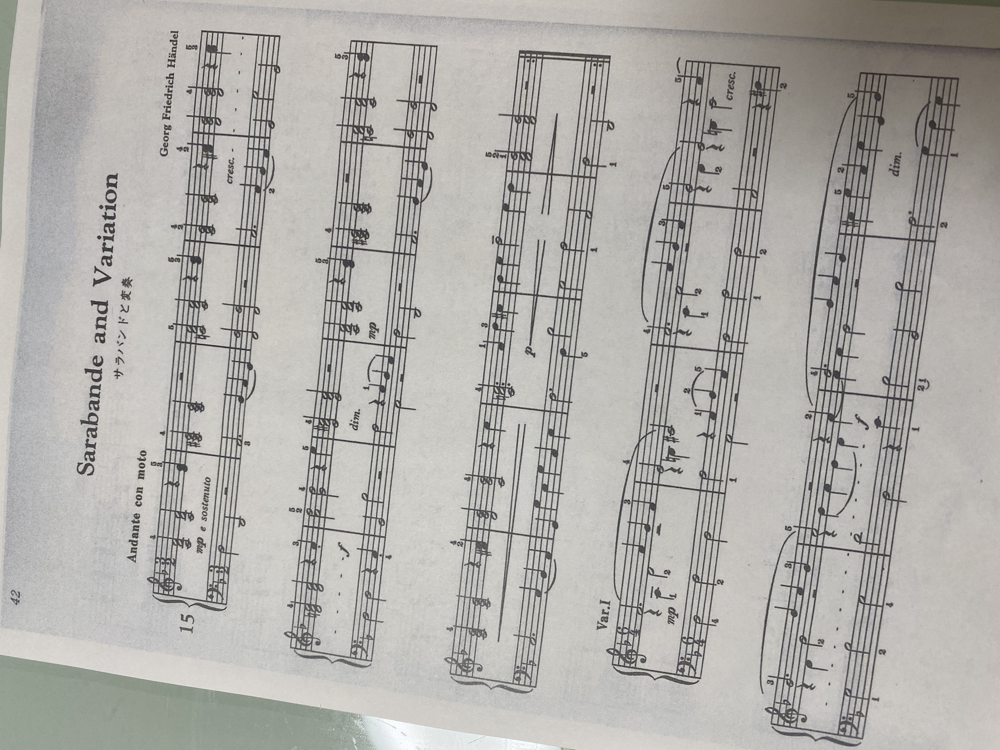

In [ ]:
#show the original image
Image(filename=FILE_PATH, width=250) 

In [ ]:
#First, level the original sheet music image
%cd /content/img2xml/bfaaap
from leveloriginalimg.leveloriginalimg import leveloriginalimg
#note that the FILE_PATH will be changed
FILE_PATH = leveloriginalimg(FILE_PATH)

/content/img2xml/bfaaap
7.992313929484442


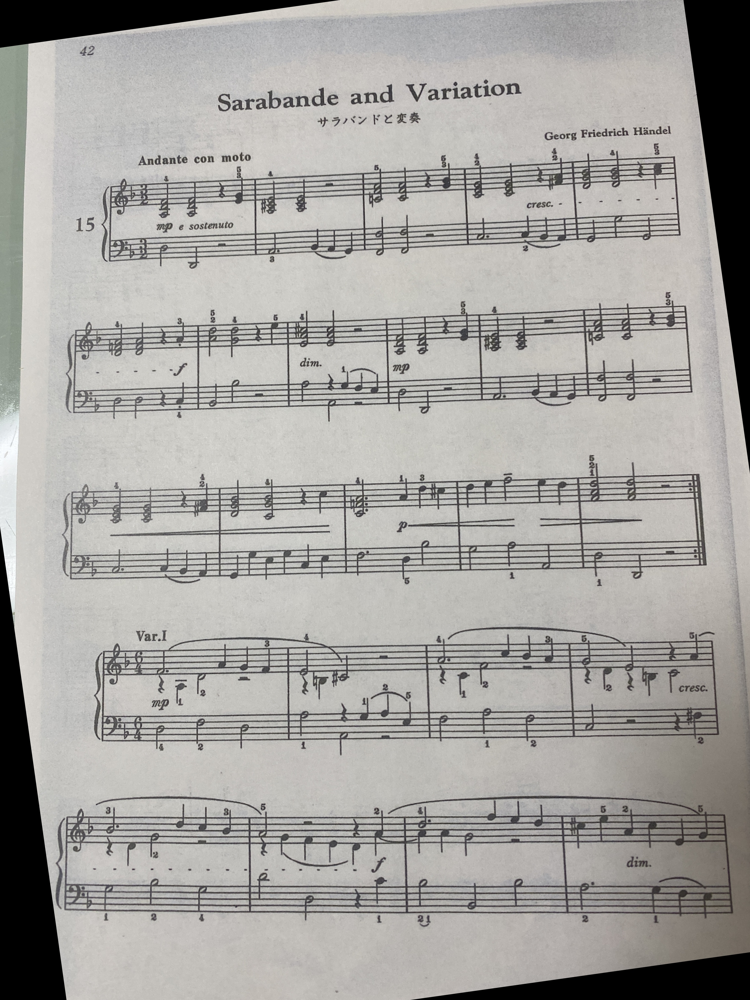

In [ ]:
#show a leveled image
Image(filename=FILE_PATH, width=250) 

In [ ]:
!pip install thop
!pip install pandas
!pip uninstall -y scipy
!pip install scipy

Looking in indexes: https://pypi.org/simple, https://us-python.pkg.dev/colab-wheels/public/simple/
Looking in indexes: https://pypi.org/simple, https://us-python.pkg.dev/colab-wheels/public/simple/
Found existing installation: scipy 1.7.3
Uninstalling scipy-1.7.3:
  Would remove:
    /usr/local/lib/python3.8/dist-packages/scipy-1.7.3.dist-info/*
    /usr/local/lib/python3.8/dist-packages/scipy.libs/libgfortran-040039e1.so.5.0.0
    /usr/local/lib/python3.8/dist-packages/scipy.libs/libopenblasp-r0-8b9e111f.3.17.so
    /usr/local/lib/python3.8/dist-packages/scipy.libs/libquadmath-96973f99.so.0.0.0
    /usr/local/lib/python3.8/dist-packages/scipy/*
Proceed (Y/n)? Y
  Successfully uninstalled scipy-1.7.3
Looking in indexes: https://pypi.org/simple, https://us-python.pkg.dev/colab-wheels/public/simple/
     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 34.5/34.5 MB 45.2 MB/s eta 0:00:00


In [ ]:
#extract staves with measures
#perform inference on sheet music
%cd /content/img2xml/bfaaap/yolov5
SAVE_DIRECTORY_PATH = os.path.dirname(FILE_PATH) + '/staff'

# proc = subprocess.Popen(['python','detect.py', '--weights', '/content/img2xml/bfaaap/yolov5/weightsstock/last_0.95_staff4_20201230.pt', '--SAVE_PATH', SAVE_DIRECTORY_PATH ,'--img', '416', '--conf', '0.75', '--source', FILE_PATH, '--save-txt'])
#print('python','detect.py', '--weights', '/content/img2xml/bfaaap/yolov5/weightsstock/last_0.95_staff4_20201230.pt', '--SAVE_PATH', SAVE_DIRECTORY_PATH ,'--img', '416', '--conf', '0.75', '--source', FILE_PATH, '--save-txt')
!python detect.py --weights /content/img2xml/bfaaap/yolov5/weightsstock/last_0.95_staff4_20201230.pt --SAVE_PATH /content/img2xml/bfaaap/musicdata/test0/staff --img 416 --conf 0.75 --source /content/img2xml/bfaaap/musicdata/test0/leveled_sarabandePhotoInclined.jpg --save-txt


/content/img2xml/bfaaap/yolov5
Namespace(SAVE_PATH='/content/img2xml/bfaaap/musicdata/test0/staff', agnostic_nms=False, augment=False, classes=None, conf_thres=0.75, device='', exist_ok=False, img_size=416, iou_thres=0.45, name='exp', project='runs/detect', save_conf=False, save_txt=True, source='/content/img2xml/bfaaap/musicdata/test0/leveled_sarabandePhotoInclined.jpg', update=False, view_img=False, weights=['/content/img2xml/bfaaap/yolov5/weightsstock/last_0.95_staff4_20201230.pt'])
SAVE_PATHは/content/img2xml/bfaaap/musicdata/test0/staff
YOLOv5  torch 1.8.1+cu102 CUDA:0 (Tesla T4, 15109.875MB)

Fusing layers... 
Model Summary: 484 layers, 88404072 parameters, 0 gradients, 219.6 GFLOPS
image 1/1 /content/img2xml/bfaaap/musicdata/test0/leveled_sarabandePhotoInclined.jpg: 416x320 5 x0s, 5 x1s, 38 y0s, Done. (0.036s)
Results saved to /content/img2xml/bfaaap/musicdata/test0/staff
1 labels saved to /content/img2xml/bfaaap/musicdata/test0/staff/labels
Done. (0.580s)


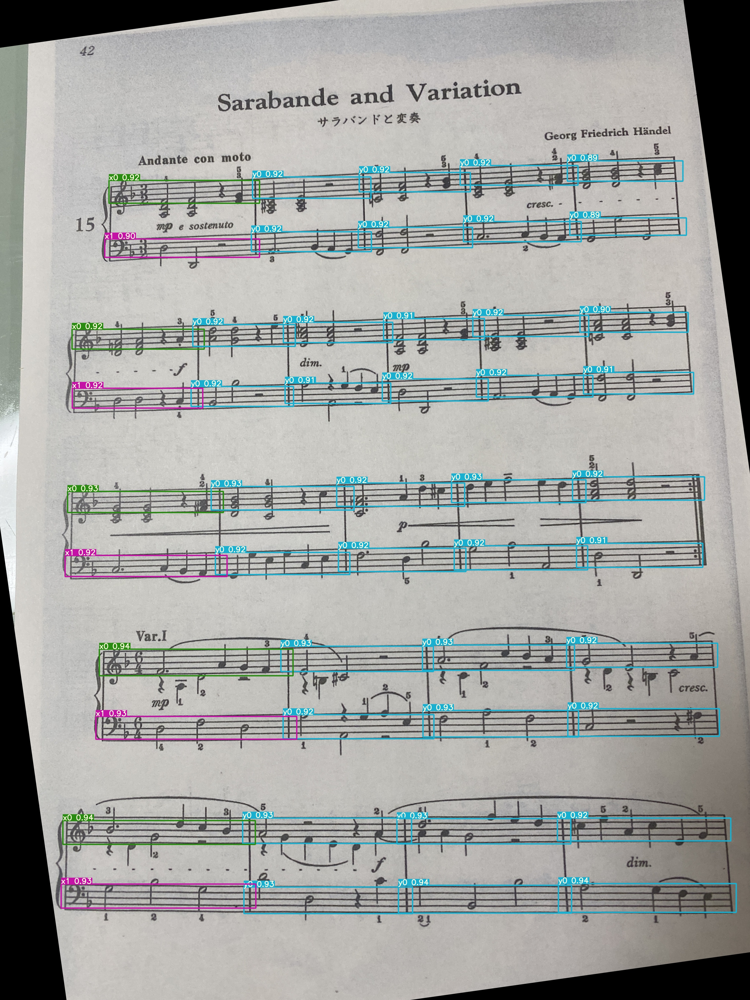

In [ ]:
# check the measure inference result
files_temp = glob.glob(FILE_PATH)
#the resulting file after inference of measures
MEASURE_INFERENCE_RESULT_PATH = ''
for file_temp in files_temp:
    if file_temp.endswith('jpg') or file_temp.endswith('png'):
        basename = os.path.basename(file_temp)
        MEASURE_INFERENCE_RESULT_PATH = SAVE_DIRECTORY_PATH + '/' + basename
#show the measure inference results on the leveled sheet music image
Image(filename=MEASURE_INFERENCE_RESULT_PATH, width=900) 

In [ ]:
#After the measure-recognizing model is applied to a piece of sheet music

#copy and move the relevant files under a dirctory ./musicdata/AAA/(staff/labels)
#sheet music (.jpg) provided in FILE_PATH
files_temp = glob.glob(FILE_PATH)
#To skip .txt files
for file_temp in files_temp:
    if file_temp.endswith('jpg') or file_temp.endswith('png'):
        img = cv2.imread(file_temp)
        dirname = os.path.dirname(file_temp)
        basename = os.path.basename(file_temp)
        cv2.imwrite(dirname + '/staff/labels/' + basename, img)


In [ ]:
#generate measures 
%cd /content/img2xml/bfaaap
from alignmeasures.align_measures import generate_measures_in_eachstave_aslist
#sheet music provided in FILE_PATH
staves_with_measures_in_sheetmusic = generate_measures_in_eachstave_aslist(FILE_PATH)
print(f'the number of staves_with_measures_in_sheetmusic is {len(staves_with_measures_in_sheetmusic)}')
for i, each_staff in enumerate(staves_with_measures_in_sheetmusic):
    print(f'the number of measures in staff{i} is {len(each_staff)}')

/content/img2xml/bfaaap
pass through deleteOverlaps(staves_input)
adjusted_staves has 10 staves
0th staff has 4 measures
staff 0: center_y is 0.191716
1th staff has 4 measures
staff 1: center_y is 0.248016
2th staff has 6 measures
staff 2: center_y is 0.339038
3th staff has 6 measures
staff 3: center_y is 0.398065
4th staff has 5 measures
staff 4: center_y is 0.50186
5th staff has 5 measures
staff 5: center_y is 0.565848
6th staff has 4 measures
staff 6: center_y is 0.662326
7th staff has 4 measures
staff 7: center_y is 0.727679
8th staff has 4 measures
staff 8: center_y is 0.832341
9th staff has 4 measures
staff 9: center_y is 0.895957
the number of staves_with_measures_in_sheetmusic is 10
the number of measures in staff0 is 4
the number of measures in staff1 is 4
the number of measures in staff2 is 6
the number of measures in staff3 is 6
the number of measures in staff4 is 5
the number of measures in staff5 is 5
the number of measures in staff6 is 4
the number of measures in staff7 i

In [ ]:
#input whether staves are paired
areStavesPaired = True

#excise and enlarge each measure img at 412 x 412 pixels in each staff and stored in musicdata/AAA/measure/staff1/ or staff2/
from enlargemeasures.enlargeeachmeasure import produceResizedMeasuresFromAlignedStaves
#in the case of wide staff extraction, set staff_magnification = 1.2
staff_magnification = 1.2

produceResizedMeasuresFromAlignedStaves(img_FILE_PATH=FILE_PATH, aligned_staves=staves_with_measures_in_sheetmusic, isPaired=areStavesPaired, upper_margin=staff_magnification, lower_margin=staff_magnification)



eachmeasure has a width of 607 and a height of 92
eachmeasure has a width of 477 and a height of 87
eachmeasure has a width of 447 and a height of 78
eachmeasure has a width of 475 and a height of 79
eachmeasure has a width of 533 and a height of 80
eachmeasure has a width of 413 and a height of 88
eachmeasure has a width of 441 and a height of 82
eachmeasure has a width of 407 and a height of 85
eachmeasure has a width of 467 and a height of 85
eachmeasure has a width of 436 and a height of 80
eachmeasure has a width of 628 and a height of 85
eachmeasure has a width of 576 and a height of 95
eachmeasure has a width of 516 and a height of 94
eachmeasure has a width of 542 and a height of 92
eachmeasure has a width of 532 and a height of 94
eachmeasure has a width of 781 and a height of 107
eachmeasure has a width of 615 and a height of 102
eachmeasure has a width of 613 and a height of 102
eachmeasure has a width of 609 and a height of 97
eachmeasure has a width of 777 and a height of 

In [ ]:
#level again each measure one by one
from leveloriginalimg.leveloriginalimg import leveleachmeasure

MEASURES_STAFF1_PATH = os.path.dirname(FILE_PATH) + '/measure/staff1/*'
files_temp = glob.glob(MEASURES_STAFF1_PATH)
for file_temp in files_temp:
    if file_temp.endswith('jpg') or file_temp.endswith('png'):
        FILE_DIR_PATH = os.path.dirname(file_temp)
        FILE_BASENAME = os.path.basename(file_temp)
        THIS_PATH = FILE_DIR_PATH + '/' + FILE_BASENAME
        result0 = leveleachmeasure(THIS_PATH)

MEASURES_STAFF2_PATH = os.path.dirname(FILE_PATH) + '/measure/staff2/*'
files_temp = glob.glob(MEASURES_STAFF2_PATH)
for file_temp in files_temp:
    if file_temp.endswith('jpg') or file_temp.endswith('png'):
        FILE_DIR_PATH = os.path.dirname(file_temp)
        FILE_BASENAME = os.path.basename(file_temp)
        THIS_PATH = FILE_DIR_PATH + '/' + FILE_BASENAME
        leveleachmeasure(THIS_PATH)

In [ ]:
#apply individual models to the measures selected for staff 1 or 2

#work at the yolov5 directory
%cd /content/img2xml/bfaaap/yolov5

#processes in series (or in parallel)
start = time.time()
print(start)
#processes = []

#image source directory path for either staff1 or staff2


#For staff1


SOURCE_PATH = os.path.dirname(FILE_PATH) + '/measure/staff1/*'

#body
print('processing body 1')
SAVE_DIRECTORY_PATH = os.path.dirname(FILE_PATH) + '/staff1/body'
proc = subprocess.Popen(['python','detect.py', '--weights', '/content/img2xml/bfaaap/yolov5/weightsstock/last_0.94_body4_20210208.pt', '--SAVE_PATH', SAVE_DIRECTORY_PATH ,'--img', '416', '--conf', '0.60', '--source', SOURCE_PATH, '--save-txt', '--device', '0'])
proc.wait()
#processes.append((0, proc))

#armbeam
print('processing armbeam 1')
SAVE_DIRECTORY_PATH = os.path.dirname(FILE_PATH) + '/staff1/armbeam'
proc = subprocess.Popen(['python','detect.py', '--weights', '/content/img2xml/bfaaap/yolov5/weightsstock/last_0.99_armbeam2_20210214.pt', '--SAVE_PATH', SAVE_DIRECTORY_PATH ,'--img', '416', '--conf', '0.60', '--source', SOURCE_PATH, '--save-txt', '--device', '0'])
proc.wait()
#processes.append((1, proc))

#accidental
print('processing accidental 1')
SAVE_DIRECTORY_PATH = os.path.dirname(FILE_PATH) + '/staff1/accidental'
proc = subprocess.Popen(['python','detect.py', '--weights', '/content/img2xml/bfaaap/yolov5/weightsstock/last_0.99_Accidental2_20210209.pt', '--SAVE_PATH', SAVE_DIRECTORY_PATH ,'--img', '416', '--conf', '0.60', '--source', SOURCE_PATH, '--save-txt'])
proc.wait()
#processes.append((2, proc))

#rest
print('processing rest 1')
SAVE_DIRECTORY_PATH = os.path.dirname(FILE_PATH) + '/staff1/rest'
proc = subprocess.Popen(['python','detect.py', '--weights', '/content/img2xml/bfaaap/yolov5/weightsstock/last_0.99_rest1_20210107.pt', '--SAVE_PATH', SAVE_DIRECTORY_PATH ,'--img', '416', '--conf', '0.60', '--source', SOURCE_PATH, '--save-txt'])
proc.wait()
#processes.append((3, proc))

#clef
print('processing clef 1')
SAVE_DIRECTORY_PATH = os.path.dirname(FILE_PATH) + '/staff1/clef'
proc = subprocess.Popen(['python','detect.py', '--weights', '/content/img2xml/bfaaap/yolov5/weightsstock/last_0.99_Clef3_20210129.pt', '--SAVE_PATH', SAVE_DIRECTORY_PATH ,'--img', '416', '--conf', '0.60', '--source', SOURCE_PATH, '--save-txt'])
proc.wait()
#processes.append((4, proc))

#For staff2

SOURCE_PATH = os.path.dirname(FILE_PATH) + '/measure/staff2/*'

#body
print('processing body 2')
SAVE_DIRECTORY_PATH = os.path.dirname(FILE_PATH) + '/staff2/body'
proc = subprocess.Popen(['python','detect.py', '--weights', '/content/img2xml/bfaaap/yolov5/weightsstock/last_0.94_body4_20210208.pt', '--SAVE_PATH', SAVE_DIRECTORY_PATH ,'--img', '416', '--conf', '0.60', '--source', SOURCE_PATH, '--save-txt'])
proc.wait()
#processes.append((5, proc))

#armbeam
print('processing armbeam 2')
SAVE_DIRECTORY_PATH = os.path.dirname(FILE_PATH) + '/staff2/armbeam'
proc = subprocess.Popen(['python','detect.py', '--weights', '/content/img2xml/bfaaap/yolov5/weightsstock/last_0.99_armbeam2_20210214.pt', '--SAVE_PATH', SAVE_DIRECTORY_PATH ,'--img', '416', '--conf', '0.60', '--source', SOURCE_PATH, '--save-txt'])
proc.wait()
#processes.append((6, proc))

#accidental
print('processing accidental 2')
SAVE_DIRECTORY_PATH = os.path.dirname(FILE_PATH) + '/staff2/accidental'
proc = subprocess.Popen(['python','detect.py', '--weights', '/content/img2xml/bfaaap/yolov5/weightsstock/last_0.99_Accidental2_20210209.pt', '--SAVE_PATH', SAVE_DIRECTORY_PATH ,'--img', '416', '--conf', '0.60', '--source', SOURCE_PATH, '--save-txt'])
proc.wait()
# processes.append((7, proc))

#rest
print('processing rest 2')
SAVE_DIRECTORY_PATH = os.path.dirname(FILE_PATH) + '/staff2/rest'
proc = subprocess.Popen(['python','detect.py', '--weights', '/content/img2xml/bfaaap/yolov5/weightsstock/last_0.99_rest1_20210107.pt', '--SAVE_PATH', SAVE_DIRECTORY_PATH ,'--img', '416', '--conf', '0.60', '--source', SOURCE_PATH, '--save-txt'])
proc.wait()
#processes.append((8, proc))

#clef
print('processing clef 2')
SAVE_DIRECTORY_PATH = os.path.dirname(FILE_PATH) + '/staff2/clef'
proc = subprocess.Popen(['python','detect.py', '--weights', '/content/img2xml/bfaaap/yolov5/weightsstock/last_0.99_Clef3_20210129.pt', '--SAVE_PATH', SAVE_DIRECTORY_PATH ,'--img', '416', '--conf', '0.60', '--source', SOURCE_PATH, '--save-txt'])
proc.wait()
# processes.append((9, proc))

#for i, p in processes:
#    print(f'waiting process {i} to finish')
#    p.wait()

#end the time measurement
elapsed_time = time.time() - start
print ("elapsed_time:{0}".format(elapsed_time) + "[sec]")

/content/img2xml/bfaaap/yolov5
1675472004.4311657
processing body 1
processing armbeam 1
processing accidental 1
processing rest 1
processing clef 1
processing body 2
processing armbeam 2
processing accidental 2
processing rest 2
processing clef 2
elapsed_time:74.77393198013306[sec]


In [ ]:
!pip uninstall -y Pillow
!pip install Pillow==8.0.1

Found existing installation: Pillow 9.0.0
Uninstalling Pillow-9.0.0:
  Successfully uninstalled Pillow-9.0.0
Looking in indexes: https://pypi.org/simple, https://us-python.pkg.dev/colab-wheels/public/simple/
  Using cached Pillow-8.0.1-cp38-cp38-manylinux1_x86_64.whl (2.2 MB)


In [ ]:
#check some of the inference results
import matplotlib.pyplot as plt
from PIL import Image
def show_images(images, figsize=(20,20), columns = 4):
  plt.figure(figsize=figsize)
  for i, image in enumerate(images):
      plt.subplot(len(images) / columns + 1, columns, i + 1)
      plt.imshow(image)

DISPLAY_FIG_PATHDIR = os.path.dirname(FILE_PATH)
images = []
featureTypes = ['body', 'armbeam', 'clef', 'accidental', 'rest']
numberOfFigs_eachType = 4

#staff1
for feature in featureTypes:
    for i in range(numberOfFigs_eachType):
        #img = Image.open(f'{DISPLAY_FIG_PATHDIR}/staff1/{feature}/measure#{i:03}.jpg')
        #images.append(img)
        pass
# #change /test0/ to your folder of interest
# img = Image.open('/content/img2xml/bfaaap/musicdata/test0/staff1/body/measure#000.jpg')
# images.append(img)

show_images(images)

<Figure size 1440x1440 with 0 Axes>

In [ ]:
images = []
"""
#staff2
for feature in featureTypes:
    for i in range(numberOfFigs_eachType):
        img = Image.open(f'{DISPLAY_FIG_PATHDIR}/staff2/{feature}/measure#{i:03}.jpg')
        images.append(img)
# #change /test0/ to your folder of interest
# img = Image.open('/content/img2xml/bfaaap/musicdata/test0/staff2/body/measure#000.jpg')
# images.append(img)

show_images(images)
"""

"\n#staff2\nfor feature in featureTypes:\n    for i in range(numberOfFigs_eachType):\n        img = Image.open(f'{DISPLAY_FIG_PATHDIR}/staff2/{feature}/measure#{i:03}.jpg')\n        images.append(img)\n# #change /test0/ to your folder of interest\n# img = Image.open('/content/img2xml/bfaaap/musicdata/test0/staff2/body/measure#000.jpg')\n# images.append(img)\n\nshow_images(images)\n"

In [ ]:
#get the file path, basename, extention

files_temp = glob.glob(FILE_PATH) #"./tmp/*":beforehand prepare images and Yolov5 anotation files in ./tmp/subdirectory
#To skip .txt files
FILE_DIR_PATH = ''
FILE_BASENAME = ''
FILE_BASENAME_WITHOUTEXT = ''
for file_temp in files_temp:
    if file_temp.endswith('jpg') or file_temp.endswith('png'):
        img = cv2.imread(file_temp)
        FILE_DIR_PATH = os.path.dirname(file_temp)
        FILE_BASENAME = os.path.basename(file_temp)
        FILE_BASENAME_WITHOUTEXT = os.path.splitext(FILE_BASENAME)[0]
        cv2.imwrite(FILE_DIR_PATH + '/staff/labels/' + FILE_BASENAME, img)

In [ ]:
%cd /content/img2xml/bfaaap
from alignmeasures.align_measures import generate_measures_in_eachstave_aslist
#sheet music provided in FILE_PATH
staves_with_measures_in_sheetmusic = generate_measures_in_eachstave_aslist(FILE_PATH)
print(f'the number of staves_with_measures_in_sheetmusic is {len(staves_with_measures_in_sheetmusic)}')
for i, each_staff in enumerate(staves_with_measures_in_sheetmusic):
    print(f'the number of measures in staff{i} is {len(each_staff)}')

/content/img2xml/bfaaap
pass through deleteOverlaps(staves_input)
adjusted_staves has 10 staves
0th staff has 4 measures
staff 0: center_y is 0.191716
1th staff has 4 measures
staff 1: center_y is 0.248016
2th staff has 6 measures
staff 2: center_y is 0.339038
3th staff has 6 measures
staff 3: center_y is 0.398065
4th staff has 5 measures
staff 4: center_y is 0.50186
5th staff has 5 measures
staff 5: center_y is 0.565848
6th staff has 4 measures
staff 6: center_y is 0.662326
7th staff has 4 measures
staff 7: center_y is 0.727679
8th staff has 4 measures
staff 8: center_y is 0.832341
9th staff has 4 measures
staff 9: center_y is 0.895957
the number of staves_with_measures_in_sheetmusic is 10
the number of measures in staff0 is 4
the number of measures in staff1 is 4
the number of measures in staff2 is 6
the number of measures in staff3 is 6
the number of measures in staff4 is 5
the number of measures in staff5 is 5
the number of measures in staff6 is 4
the number of measures in staff7 i

In [ ]:
#input wheter staves are paired
areStavesPaired = True

In [ ]:
#generate ms sequence in each staff

from makeyolomusicdict.generatedictforxml import give_all_ms_in_eachmeasure_for_staff1or2

all_ms_in_eachmeasure_staff1, all_ms_in_eachmeasure_staff2 = give_all_ms_in_eachmeasure_for_staff1or2(isPaired=areStavesPaired, aligned_staves_input=staves_with_measures_in_sheetmusic, img_FILE_PATH=FILE_PATH)
print(f'the number of items in all_ms_in_eachmeasure_staff1 is {len(all_ms_in_eachmeasure_staff1)}')
aaa1 = all_ms_in_eachmeasure_staff1['measure#001']
print(f'aaa1 is {aaa1}')
print(f'the number of items in all_ms_in_eachmeasure_staff2 is {len(all_ms_in_eachmeasure_staff2)}')
bbb1 = all_ms_in_eachmeasure_staff2['measure#001']
print(f'bbb1 is {bbb1}')

the number of itmes in measures_in_staff1 is 23
the number of items in measures_in_staff2 is 23
are measures_in_staff1 and measures_in_staff２ identical?: False
the number of items in type_of_eachmeasure_staff1 is 23
type_of_eachmeasure_staff1 is {'measure#000': <MeasureType.x0: 1>, 'measure#001': <MeasureType.y0: 3>, 'measure#002': <MeasureType.y0: 3>, 'measure#003': <MeasureType.y0: 3>, 'measure#004': <MeasureType.x0: 1>, 'measure#005': <MeasureType.y0: 3>, 'measure#006': <MeasureType.y0: 3>, 'measure#007': <MeasureType.y0: 3>, 'measure#008': <MeasureType.y0: 3>, 'measure#009': <MeasureType.y0: 3>, 'measure#010': <MeasureType.x0: 1>, 'measure#011': <MeasureType.y0: 3>, 'measure#012': <MeasureType.y0: 3>, 'measure#013': <MeasureType.y0: 3>, 'measure#014': <MeasureType.y0: 3>, 'measure#015': <MeasureType.x0: 1>, 'measure#016': <MeasureType.y0: 3>, 'measure#017': <MeasureType.y0: 3>, 'measure#018': <MeasureType.y0: 3>, 'measure#019': <MeasureType.x0: 1>, 'measure#020': <MeasureType.y0: 3

In [ ]:
#This information has been moved to the location where FILE_PATH was input
# #input base data for sheet music of interest:
# tempo = 120 #public data
# fifths = -1 #public data
# beats = 3 #public data
# beat_type = 2 #public data
# preset_measure_duration = 1024 * beats / beat_type #public data

#additional parameters
staff = 1
isWideStaff = False

In [ ]:
from makeyolomusicdict.generatedictforxml import setCurrentAccidentalTable, generateMSsequenceForStaff1or2, Clef

#classはimportすること
current_clef = Clef.G
current_accidental_table_template ={'A':'', 'B':'', 'C':'', 'D':'', 'E':'', 'F':'', 'G':''}
current_accidental_table = setCurrentAccidentalTable(current_accidental_table_template, fifths)
ms_sequenceOfInterest_staff1 = generateMSsequenceForStaff1or2(all_ms_in_eachmeasure_input=all_ms_in_eachmeasure_staff1, current_accidental_table_input=current_accidental_table, staff=1, current_clef_input=current_clef, preset_measure_duration=preset_measure_duration, FILE_PATH=FILE_PATH, isWideStaff=isWideStaff)

#for staff2: check current_clef
current_clef = Clef.F
ms_sequenceOfInterest_staff2 = generateMSsequenceForStaff1or2(all_ms_in_eachmeasure_input=all_ms_in_eachmeasure_staff2, current_accidental_table_input=current_accidental_table, staff=2, current_clef_input=current_clef, preset_measure_duration=preset_measure_duration, FILE_PATH=FILE_PATH, isWideStaff=isWideStaff)

print(f'the number of items in all_ms_in_eachmeasure_staff1 is {len(all_ms_in_eachmeasure_staff1)}')
print(f'the number of items in all_ms_in_eachmeasure_staff2 is {len(all_ms_in_eachmeasure_staff2)}')

print(f'the number of items in ms_sequenceOfInterest_staff1 is {len(ms_sequenceOfInterest_staff1)}')
print(f'the number of items in ms_sequenceOfInterest_staff2 is {len(ms_sequenceOfInterest_staff2)}')

measure#000: alpha is 0.02 and beta is -0.003
the number of items in hsMSlist is 14
hsMSlist[0]["measuretype"] is MeasureType.x0; the category is Category.cf0
pitchClass changed is B









duration adjustment is not carried out
measure#001: alpha is -0.009 and beta is 0.0
the number of items in hsMSlist is 10
hsMSlist[0]["measuretype"] is MeasureType.y0; the category is Category.ac0






duration adjustment is not carried out
measure#002: alpha is -0.009 and beta is 0.002
the number of items in hsMSlist is 13
hsMSlist[0]["measuretype"] is MeasureType.y0; the category is Category.ac2










duration adjustment is not carried out
measure#003: alpha is 0.02 and beta is 0.002
the number of items in hsMSlist is 14
hsMSlist[0]["measuretype"] is MeasureType.y0; the category is Category.bd2










duration adjustment is not carried out
measure#004: alpha is -0.009 and beta is 0.002
the number of items in hsMSlist is 14
hsMSlist[0]["measuretype"] is MeasureType.x0; the category is Cat

In [ ]:
# generate a dictionary for ET

from makeyolomusicdict.generatedictforxml import generateDictForET_singlestaff

#for staff1
current_staff1_clef = Clef.G
dictionary_for_ET_staff1 = generateDictForET_singlestaff(ms_sequenceOfInterest_staff_input=ms_sequenceOfInterest_staff1, tempo=tempo, beats=beats, beat_type=beat_type, fifths=fifths, clef=current_staff1_clef)
part_content1 = dictionary_for_ET_staff1['part']
print(f'the number of items in dictionary_for_ET_staff1[0] is \n{len(part_content1)}')
#for staff2
current_staff2_clef = Clef.F
dictionary_for_ET_staff2 = generateDictForET_singlestaff(ms_sequenceOfInterest_staff_input=ms_sequenceOfInterest_staff2, tempo=tempo, beats=beats, beat_type=beat_type, fifths=fifths, clef=current_staff2_clef)
part_content2 = dictionary_for_ET_staff2['part']
print(f'the number of items in dictionary_for_ET_staff2[0] is \n{len(part_content2)}')

print(f'current_staff1_clef:{current_staff1_clef}\ncurrent_staff2_clef:{current_staff2_clef}')


the number of items in dictionary_for_ET_staff1[0] is 
23
the number of items in dictionary_for_ET_staff2[0] is 
23
current_staff1_clef:Clef.G
current_staff2_clef:Clef.F


In [ ]:
#generate XML
from yoloToxml.yoloToxml import musicData2XML
import xml.etree.ElementTree as ET
from xml.dom import minidom


#for staff1

part_et = ET.Element('part')
part_et.attrib = {'id':'P1'}
part_et_1 = musicData2XML(part_et, dictionary_for_ET_staff1)

xmlstr_1 = minidom.parseString(ET.tostring(part_et_1)).toprettyxml(indent="   ")

#to delete <?xml version="1.0"　?> in line 1
xmlstr_1 = xmlstr_1[23:]
            

#read template.xml to prepare part_et XML data and generate the whole XML
wholeXML_staff1_text = ""
with open("/content/img2xml/bfaaap/yoloToxml/template.xml", 'r') as f:
    template_text = f.read()
    wholeXML_staff1_text = template_text +'\n' + xmlstr_1 +'\n</score-partwise>'

#save the resulting xml in ./xml/ directory
FILE_DIR_PATH
new_dir_path = FILE_DIR_PATH + '/xml'
os.makedirs(new_dir_path, exist_ok=True)
new_xml_filepath = new_dir_path + '/' + FILE_BASENAME_WITHOUTEXT + '_staff1.xml'
with open(new_xml_filepath, 'w') as f:
    f.write(wholeXML_staff1_text)

In [ ]:
#for staff2

part_et = ET.Element('part')
part_et.attrib = {'id':'P1'}
part_et_2 = musicData2XML(part_et, dictionary_for_ET_staff2)

xmlstr_2 = minidom.parseString(ET.tostring(part_et_2)).toprettyxml(indent="   ")

#to delete <?xml version="1.0"　?> in line 1
xmlstr_2 = xmlstr_2[23:]            

#read template.xml to prepare part_et XML data and generate the whole XML
wholeXML_staff2_text = ""
with open("/content/img2xml/bfaaap/yoloToxml/template.xml", 'r') as f:
    template_text = f.read()
    wholeXML_staff2_text = template_text +'\n' + xmlstr_2 +'\n</score-partwise>'

#save the resulting xml in ./xml/ directory
FILE_DIR_PATH
new_dir_path = FILE_DIR_PATH + '/xml'
os.makedirs(new_dir_path, exist_ok=True)
new_xml_filepath = new_dir_path + '/' + FILE_BASENAME_WITHOUTEXT + '_staff2.xml'
with open(new_xml_filepath, 'w') as f:
    f.write(wholeXML_staff2_text)


# download the resulting xml file from "/content/img2xml/bfaaap/musicdata/test0/xml/*.xml"

### Use, for instance, [Logic Pro](https://www.apple.com/jp/logic-pro/), [MuseScore](https://musescore.org/), [Sibelius First](https://my.avid.com/get/sibelius-first)
